# HAM10000 Exploratory Data Analysis (EDA)

สมุดงานวิเคราะห์และสำรวจชุดข้อมูล HAM10000 Skin Lesion (10,015 รูปภาพ, 7 คลาส)
- ตรวจสอบโครงสร้าง, Channels, มิติภาพ, และฟีเจอร์ใน Metadata
- พล็อตกราฟการแจกแจงคลาสโรค (Class Imbalance)
- ตรวจสอบความสม่ำเสมอของ Train / Val / Test (70/15/15 Stratified Split)
- แสดงภาพถ่ายรอยโรคจริงทั้ง 7 โรคเปรียบเทียบกัน
- ตรวจสอบภาพหลังผ่าน On-the-fly Data Augmentation

In [1]:
# =========================================================================
# 1. โหลดข้อมูล Metadata และตรวจสอบสเปกพื้นฐาน (ขนาด, แชนเนล, ฟีเจอร์)
# =========================================================================
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

from src.dataset import CLASSES, CLASS_TO_IDX

meta_df = pd.read_csv('data/HAM10000_metadata.csv')
splits_df = pd.read_csv('splits/splits.csv')

# ตรวจสอบตัวอย่างไฟล์ภาพจริง 1 ภาพ
sample_img_id = meta_df.iloc[0]['image_id']
sample_path = Path('data/HAM10000_images_part_1') / f"{sample_img_id}.jpg"
if not sample_path.exists():
    sample_path = Path('data/HAM10000_images_part_2') / f"{sample_img_id}.jpg"

with Image.open(sample_path) as img:
    width, height = img.size
    mode = img.mode
    channels = len(img.getbands())

print('=' * 60)
print('DATASET OVERVIEW & SPECIFICATIONS')
print('=' * 60)
print(f"จำนวนแถวข้อมูล Metadata : {len(meta_df):,} แถว")
print(f"จำนวนรอยโรคจริง        : {meta_df['lesion_id'].nunique():,} รอยโรค")
print(f"ขนาดภาพต้นฉบับ         : {width} x {height} พิกเซล")
print(f"โหมดสีและจำนวน Channels: {mode} ({channels} แชนเนล RGB)")
print(f"คอลัมน์ใน Metadata     : {meta_df.columns.tolist()}")
print(f"จำนวนคลาสเป้าหมาย      : {len(CLASSES)} คลาส ({CLASSES})")
print('=' * 50)
print('สถิติอายุผู้ป่วย (Age Statistics)')
print('=' * 50)
print(f"อายุเฉลี่ย (Mean)     : {meta_df['age'].mean():.2f} ปี")
print(f"อายุมัธยฐาน (Median)  : {meta_df['age'].median():.1f} ปี")
print(f"อายุน้อยสุด - มากสุด  : {meta_df['age'].min():.0f} - {meta_df['age'].max():.0f} ปี")
print(f"ข้อมูลอายุที่ว่าง (NaN) : {meta_df['age'].isna().sum()} รูป")
print('=' * 60)
meta_df.head()

DATASET OVERVIEW & SPECIFICATIONS
จำนวนแถวข้อมูล Metadata : 10,015 แถว
จำนวนรอยโรคจริง        : 7,470 รอยโรค
ขนาดภาพต้นฉบับ         : 600 x 450 พิกเซล
โหมดสีและจำนวน Channels: RGB (3 แชนเนล RGB)
คอลัมน์ใน Metadata     : ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
จำนวนคลาสเป้าหมาย      : 7 คลาส (['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'])
สถิติอายุผู้ป่วย (Age Statistics)
อายุเฉลี่ย (Mean)     : 51.86 ปี
อายุมัธยฐาน (Median)  : 50.0 ปี
อายุน้อยสุด - มากสุด  : 0 - 85 ปี
ข้อมูลอายุที่ว่าง (NaN) : 57 รูป


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [2]:
print('\n' + '=' * 50)
print('ตำแหน่งรอยโรคบนร่างกาย (Localization Counts)')
print('=' * 50)
loc_counts = meta_df['localization'].value_counts()
for loc, count in loc_counts.items():
    pct = (count / len(meta_df)) * 100
    print(f"{loc:<18} : {count:>5} ภาพ ({pct:>5.2f}%)")


ตำแหน่งรอยโรคบนร่างกาย (Localization Counts)
back               :  2192 ภาพ (21.89%)
lower extremity    :  2077 ภาพ (20.74%)
trunk              :  1404 ภาพ (14.02%)
upper extremity    :  1118 ภาพ (11.16%)
abdomen            :  1022 ภาพ (10.20%)
face               :   745 ภาพ ( 7.44%)
chest              :   407 ภาพ ( 4.06%)
foot               :   319 ภาพ ( 3.19%)
unknown            :   234 ภาพ ( 2.34%)
neck               :   168 ภาพ ( 1.68%)
scalp              :   128 ภาพ ( 1.28%)
hand               :    90 ภาพ ( 0.90%)
ear                :    56 ภาพ ( 0.56%)
genital            :    48 ภาพ ( 0.48%)
acral              :     7 ภาพ ( 0.07%)


/tmp/ipykernel_1653/1678751361.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')


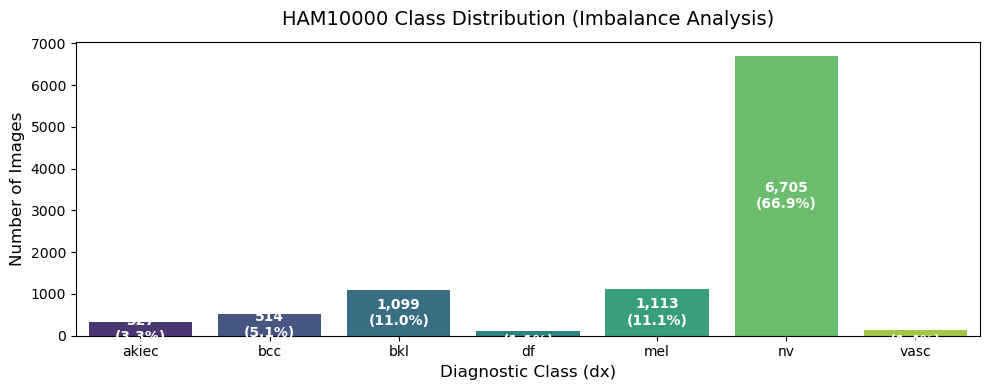

In [3]:
# =========================================================================
# 2. พล็อตกราฟแจกแจงจำนวนแต่ละคลาส (ตรวจสอบ Severe Class Imbalance)
# =========================================================================
plt.figure(figsize=(10, 4))
class_counts = meta_df['dx'].value_counts()[CLASSES]

ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('HAM10000 Class Distribution (Imbalance Analysis)', fontsize=14, pad=12)
plt.xlabel('Diagnostic Class (dx)', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)

for p in ax.patches:
    height = int(p.get_height())
    pct = (height / len(meta_df)) * 100
    ax.annotate(f"{height:,}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

<Figure size 1000x400 with 0 Axes>

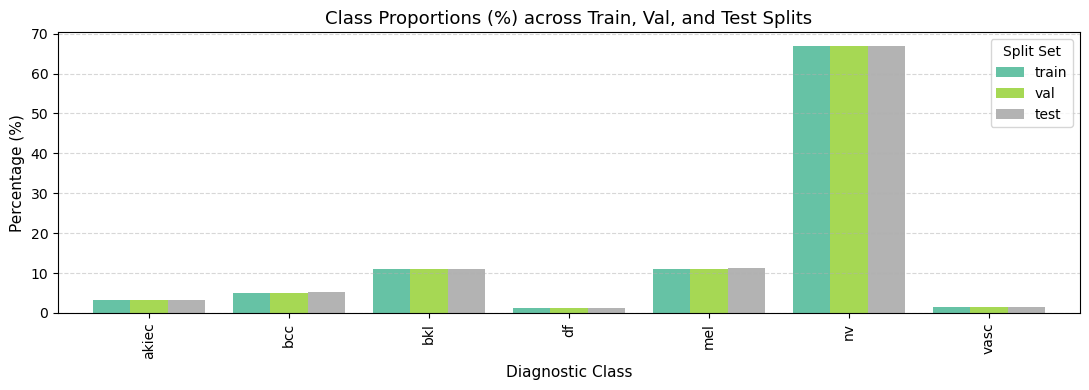

split  train   val  test  Total
dx                             
akiec    228    50    49    327
bcc      359    77    78    514
bkl      769   165   165   1099
df        80    18    17    115
mel      779   166   168   1113
nv      4694  1006  1005   6705
vasc     100    21    21    142


In [4]:
# =========================================================================
# 3. ตรวจสอบสัดส่วน Train / Val / Test (70 / 15 / 15 Stratified Consistency)
# =========================================================================
split_class_df = pd.crosstab(splits_df['dx'], splits_df['split'], normalize='columns')[['train', 'val', 'test']] * 100

plt.figure(figsize=(10, 4))
split_class_df.loc[CLASSES].plot(kind='bar', figsize=(11, 4), colormap='Set2', width=0.8)
plt.title('Class Proportions (%) across Train, Val, and Test Splits', fontsize=13)
plt.xlabel('Diagnostic Class', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)
plt.legend(title='Split Set')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# สรุปตารางตัวเลข
counts_summary = pd.crosstab(splits_df['dx'], splits_df['split'])[['train', 'val', 'test']]
counts_summary['Total'] = counts_summary.sum(axis=1)
print(counts_summary.loc[CLASSES])

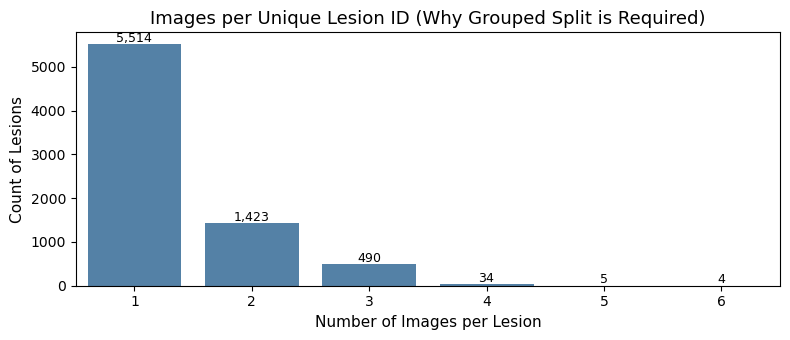

In [5]:
# =========================================================================
# 4. พล็อตสถิติการถ่ายรูปซ้ำต่อรอยโรค (ทำไมต้องแบ่งแบบ Grouped by lesion_id)
# =========================================================================
images_per_lesion = meta_df.groupby('lesion_id').size()
lesion_counts = images_per_lesion.value_counts().sort_index()

plt.figure(figsize=(8, 3.5))
sns.barplot(x=lesion_counts.index, y=lesion_counts.values, color='steelblue')
plt.title('Images per Unique Lesion ID (Why Grouped Split is Required)', fontsize=13)
plt.xlabel('Number of Images per Lesion', fontsize=11)
plt.ylabel('Count of Lesions', fontsize=11)

for p in plt.gca().patches:
    h = int(p.get_height())
    plt.gca().annotate(f"{h:,}", (p.get_x() + p.get_width() / 2., h + 50), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

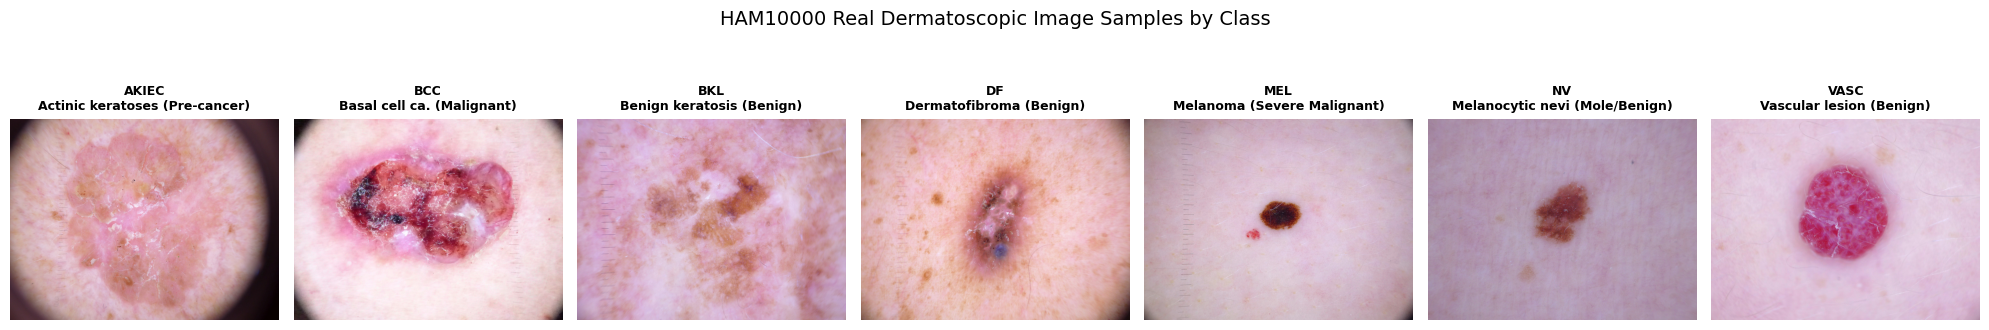

In [6]:
# =========================================================================
# 5. แสดงภาพถ่ายรอยโรคผิวหนังจริงทั้ง 7 คลาส (Sample Grid Visualization)
# =========================================================================
class_desc = {
    'akiec': 'Actinic keratoses (Pre-cancer)',
    'bcc': 'Basal cell ca. (Malignant)',
    'bkl': 'Benign keratosis (Benign)',
    'df': 'Dermatofibroma (Benign)',
    'mel': 'Melanoma (Severe Malignant)',
    'nv': 'Melanocytic nevi (Mole/Benign)',
    'vasc': 'Vascular lesion (Benign)',
}

fig, axes = plt.subplots(1, 7, figsize=(20, 3.5))

for idx, cls_name in enumerate(CLASSES):
    sample_row = meta_df[meta_df['dx'] == cls_name].iloc[0]
    img_id = sample_row['image_id']
    path = Path('data/HAM10000_images_part_1') / f"{img_id}.jpg"
    if not path.exists():
        path = Path('data/HAM10000_images_part_2') / f"{img_id}.jpg"
    
    with Image.open(path) as img:
        axes[idx].imshow(img)
    axes[idx].set_title(f"{cls_name.upper()}\n{class_desc[cls_name]}", fontsize=9, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('HAM10000 Real Dermatoscopic Image Samples by Class', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

สรุปเทคนิค Data Augmentation ทั้งหมดใน src/augment.py (get_train_transform):
1. RandomHorizontalFlip(p=0.5)      : สุ่มพลิกภาพแนวนอน (ซ้าย-ขวา) 50%
2. RandomVerticalFlip(p=0.5)        : สุ่มพลิกภาพแนวตั้ง (บน-ล่าง) 50% (รอยโรคไม่มีทิศทางตายตัว)
3. RandomRotation(degrees=180)      : สุ่มหมุนภาพอิสระได้ถึง 180 องศา
4. RandomResizedCrop(scale=0.8-1.0) : สุ่มครอบภาพ 80-100% แล้วขยายกลับเป็น 224x224 (จำลองระยะซูม)
5. ColorJitter(B,C,S=0.15, H=0.03)  : สุ่มความสว่าง, คอนทราสต์, ความอิ่มสี +/-15%, ฮิว +/-3%
6. ToTensor() + Normalize(ImageNet) : แปลงเป็น PyTorch Tensor และ Normalize ค่าสี Mean/Std


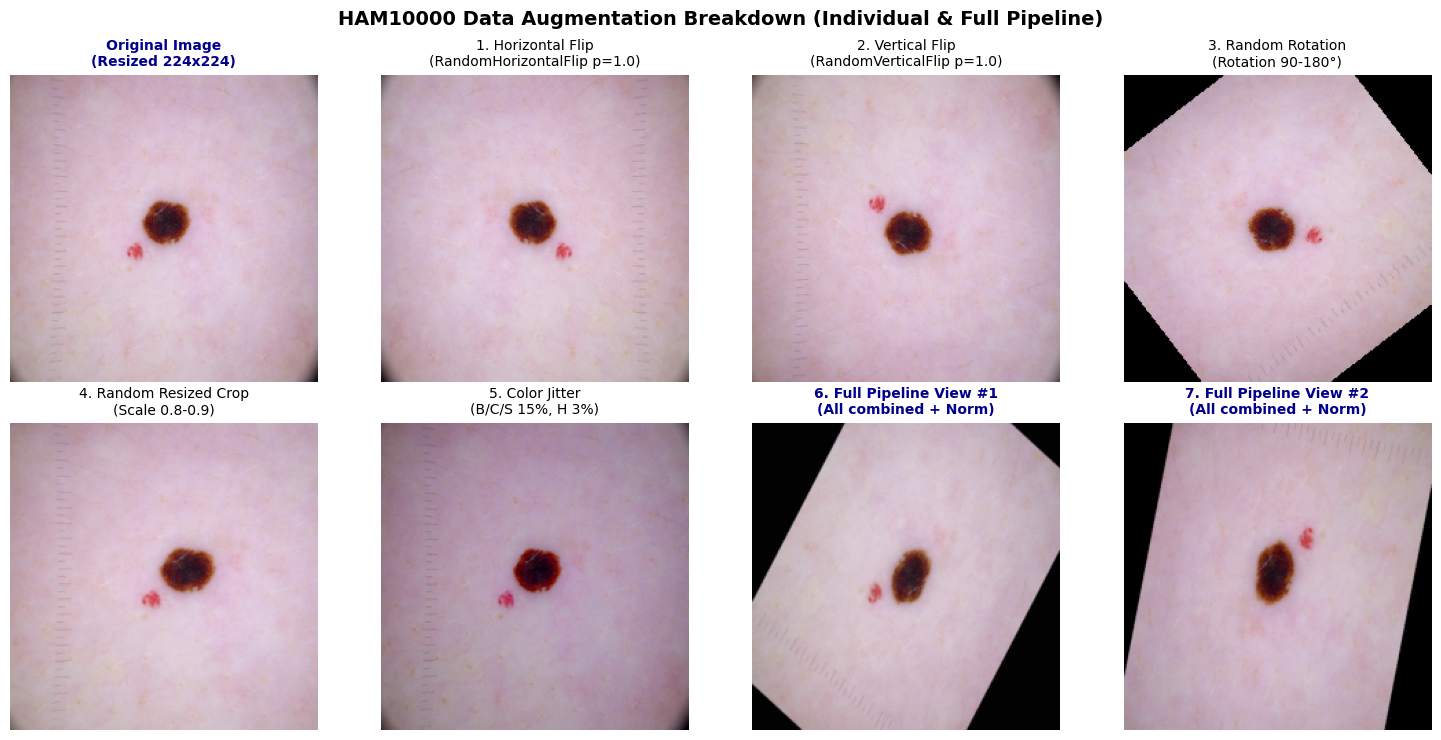

In [7]:
# =========================================================================
# 6. ตรวจสอบผลลัพธ์ Data Augmentation (แยกทีละเทคนิค & รวม Full Pipeline)
# =========================================================================
import numpy as np
import torch
from torchvision import transforms
from src.augment import get_train_transform, IMAGENET_MEAN, IMAGENET_STD

print("=" * 75)
print("สรุปเทคนิค Data Augmentation ทั้งหมดใน src/augment.py (get_train_transform):")
print("=" * 75)
print("1. RandomHorizontalFlip(p=0.5)      : สุ่มพลิกภาพแนวนอน (ซ้าย-ขวา) 50%")
print("2. RandomVerticalFlip(p=0.5)        : สุ่มพลิกภาพแนวตั้ง (บน-ล่าง) 50% (รอยโรคไม่มีทิศทางตายตัว)")
print("3. RandomRotation(degrees=180)      : สุ่มหมุนภาพอิสระได้ถึง 180 องศา")
print("4. RandomResizedCrop(scale=0.8-1.0) : สุ่มครอบภาพ 80-100% แล้วขยายกลับเป็น 224x224 (จำลองระยะซูม)")
print("5. ColorJitter(B,C,S=0.15, H=0.03)  : สุ่มความสว่าง, คอนทราสต์, ความอิ่มสี +/-15%, ฮิว +/-3%")
print("6. ToTensor() + Normalize(ImageNet) : แปลงเป็น PyTorch Tensor และ Normalize ค่าสี Mean/Std")
print("=" * 75)

# ฟังก์ชันถอด Normalize กลับมาเป็นภาพสีสำหรับพล็อต
def denormalize(tensor):
    t = tensor.clone().detach().cpu()
    for c in range(3):
        t[c] = t[c] * IMAGENET_STD[c] + IMAGENET_MEAN[c]
    t = torch.clamp(t, 0.0, 1.0)
    return t.permute(1, 2, 0).numpy()

mel_sample = meta_df[meta_df["dx"] == "mel"].iloc[0]["image_id"]
img_path = Path("data/HAM10000_images_part_1") / f"{mel_sample}.jpg"
if not img_path.exists():
    img_path = Path("data/HAM10000_images_part_2") / f"{mel_sample}.jpg"

orig_img = Image.open(img_path).convert("RGB")
resized_orig = orig_img.resize((224, 224))

# รายการเปรียบเทียบการแปลงภาพทีละเทคนิคเดี่ยวๆ และแบบผสมทั้ง Pipeline
demo_aug_list = [
    ("Original Image\n(Resized 224x224)", resized_orig),
    ("1. Horizontal Flip\n(RandomHorizontalFlip p=1.0)", transforms.RandomHorizontalFlip(p=1.0)(resized_orig)),
    ("2. Vertical Flip\n(RandomVerticalFlip p=1.0)", transforms.RandomVerticalFlip(p=1.0)(resized_orig)),
    ("3. Random Rotation\n(Rotation 90-180°)", transforms.RandomRotation(degrees=(90, 180))(resized_orig)),
    ("4. Random Resized Crop\n(Scale 0.8-0.9)", transforms.RandomResizedCrop(size=224, scale=(0.8, 0.9))(orig_img)),
    ("5. Color Jitter\n(B/C/S 15%, H 3%)", transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.04)(resized_orig)),
    ("6. Full Pipeline View #1\n(All combined + Norm)", denormalize(get_train_transform(224)(orig_img))),
    ("7. Full Pipeline View #2\n(All combined + Norm)", denormalize(get_train_transform(224)(orig_img))),
]

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
axes = axes.flatten()

for idx, (title, img_data) in enumerate(demo_aug_list):
    axes[idx].imshow(img_data)
    is_highlight = (idx == 0 or idx >= 6)
    axes[idx].set_title(title, fontsize=10, fontweight="bold" if is_highlight else "normal", color="darkblue" if is_highlight else "black")
    axes[idx].axis("off")

plt.suptitle("HAM10000 Data Augmentation Breakdown (Individual & Full Pipeline)", fontsize=14, y=0.98, fontweight="bold")
plt.tight_layout()
plt.show()
